# Задача 4.3 — Бросание монеты до первого герба

---

## 1. Условие

«Симметричную» монету бросают до первого появления герба. Найдите вероятность события $A$: потребуется не более пяти бросаний.

---

## 2. Теоретическая часть

Пусть $X$ — номер бросания, на котором впервые выпал герб. Тогда $X$ имеет геометрическое распределение:

$$
P(X = k) = \left(\tfrac{1}{2}\right)^{k}, \qquad k = 1, 2, \dots
$$

Искомая вероятность:

$$
P(A) = P(X \le 5) = \sum_{k=1}^{5} \left(\tfrac{1}{2}\right)^{k}
= 1 - \left(\tfrac{1}{2}\right)^{5} = \frac{31}{32}.
$$

---

## 3. Решение

P(A) = 0.96875 = 31/32


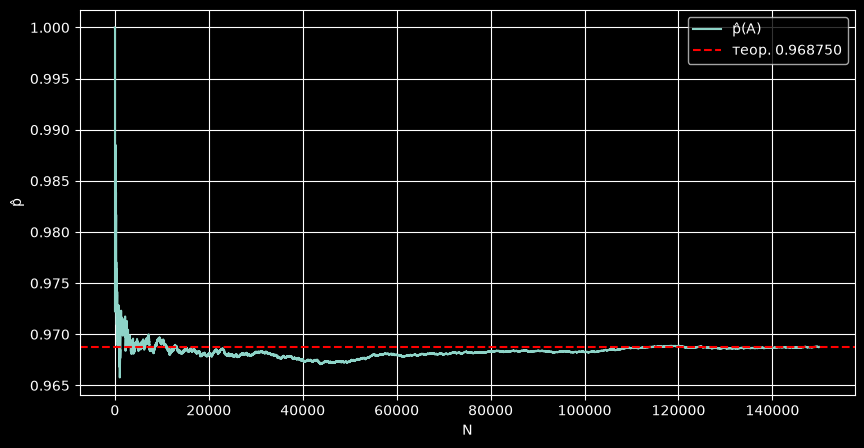

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Точный ответ ----------
P_A = sum(0.5**k for k in range(1, 6))
print(f"P(A) = {P_A} = 31/32")

# ---------- Моделирование ----------
def simulate(N, seed=0):
    rng = np.random.default_rng(seed)
    hits = np.zeros(N, dtype=bool)
    for i in range(N):
        k = 0
        while True:
            k += 1
            if rng.random() < 0.5:     # герб
                break
        hits[i] = (k <= 5)
    return hits

N = 150_000
h = simulate(N, seed=2)
f = np.cumsum(h) / np.arange(1, N+1)

plt.figure(figsize=(10, 5))
plt.plot(f, label="p̂(A)")
plt.axhline(P_A, color="r", ls="--", label=f"теор. {P_A:.6f}")
plt.xlabel("N"); plt.ylabel("p̂"); plt.legend(); plt.grid(True)
plt.show()